# 03 — Grad-CAM Explainability & Faithfulness Verification

* **Goal:** Implement Gradient-weighted Class Activation Mapping (Grad-CAM) on `model.features[-1]` of our fine-tuned MobileNetV3-Large checkpoint, verify hook cleanup, class-discriminative localization, and deletion faithfulness, and render attention galleries.
* **Inputs:** `models/mobilenetv3_food25.pt`, `models/class_names.json`, Food-101 test split.
* **Outputs:** Visual verification galleries and the canonical `GradCAM` reference implementation mirrored in `backend/app/services/gradcam.py`.
* **Expected Runtime:** ~1–2 min on CPU or GPU.

In [1]:
from __future__ import annotations

import os
import random
import sys
from pathlib import Path
from typing import Optional

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torchvision import models

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

In [2]:
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from _shared.paths import DATA, MODELS, RAW, ROOT
from _shared.datasets import class_names, get_subset_samples, load_rgb
from _shared.transforms import IMG_SIZE, RESIZE_SHORT, eval_numpy

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
)
FAST_DEV = os.environ.get("FAST_DEV", "0") == "1"
print(f"Selected device: {DEVICE} (Grad-CAM runs in FP32 with gradients enabled)")

Selected device: cpu (Grad-CAM runs in FP32 with gradients enabled)


## 1. Grad-CAM Formulation

For target class $c$, pre-softmax logit $y^c$, and last convolutional feature maps $A^k \in \mathbb{R}^{u \times v}$ (`model.features[-1]`, $960$ channels of $7 \times 7$ at $224 \times 224$ input):
$$\alpha_k^c=\frac{1}{Z}\sum_{i}\sum_{j}\frac{\partial y^c}{\partial A^k_{ij}},\qquad L^c_{\text{Grad-CAM}}=\mathrm{ReLU}\Bigl(\sum_k \alpha_k^c A^k\Bigr)$$
We normalize into $[0, 1]$ via:
$$\hat L=\dfrac{L-\min L}{\max L-\min L+\epsilon}$$

### Hook & In-Place Safety
PyTorch's `register_full_backward_hook` can conflict with in-place activations (`Hardswish(inplace=True)`, `ReLU(inplace=True)`). We therefore:
1. Disable all in-place flags across the network via `disable_inplace(model)`.
2. Register a **forward hook** on `model.features[-1]` that captures the forward activation tensor and attaches `output.register_hook(...)` directly to the tensor, removing the handle in `__exit__`.

In [3]:
EPS = 1e-8


def disable_inplace(model: nn.Module) -> None:
    for m in model.modules():
        if isinstance(m, (nn.ReLU, nn.ReLU6, nn.Hardswish, nn.Hardsigmoid, nn.SiLU, nn.Dropout)) and hasattr(m, "inplace"):
            m.inplace = False


def crop_geometry(h: int, w: int, resize_short: int = RESIZE_SHORT, crop: int = IMG_SIZE) -> tuple[int, int, int, int]:
    scale = resize_short / min(h, w)
    new_w = max(crop, int(round(w * scale)))
    new_h = max(crop, int(round(h * scale)))
    return new_h, new_w, (new_h - crop) // 2, (new_w - crop) // 2


class GradCAM:
    def __init__(self, model: nn.Module, layer: nn.Module) -> None:
        self.model = model
        self.layer = layer
        self._handle: Optional[torch.utils.hooks.RemovableHandle] = None
        self.activations: Optional[torch.Tensor] = None
        self.gradients: Optional[torch.Tensor] = None

    def __enter__(self) -> "GradCAM":
        def forward_hook(_module: nn.Module, _inp: tuple, output: torch.Tensor) -> None:
            self.activations = output
            if output.requires_grad:
                output.register_hook(self._save_grad)

        self._handle = self.layer.register_forward_hook(forward_hook)
        return self

    def __exit__(self, *exc: object) -> None:
        if self._handle is not None:
            self._handle.remove()
            self._handle = None
        self.activations = None
        self.gradients = None

    def _save_grad(self, grad: torch.Tensor) -> None:
        self.gradients = grad

    def __call__(self, x: torch.Tensor, target_index: Optional[int] = None) -> tuple[np.ndarray, int]:
        was_training = self.model.training
        self.model.eval()
        try:
            with torch.enable_grad():
                self.model.zero_grad(set_to_none=True)
                logits = self.model(x)
                if target_index is None:
                    target_index = int(logits.argmax(dim=1).item())
                score = logits[0, target_index]
                score.backward()
            if self.activations is None or self.gradients is None:
                raise RuntimeError("Grad-CAM hooks did not capture activations/gradients.")
            acts = self.activations.detach()[0]
            grads = self.gradients.detach()[0]
            weights = grads.mean(dim=(1, 2), keepdim=True)
            cam = torch.relu((weights * acts).sum(dim=0))
            cam = (cam - cam.min()) / (cam.max() - cam.min() + EPS)
            return cam.cpu().numpy().astype(np.float32), int(target_index)
        finally:
            self.model.zero_grad(set_to_none=True)
            self.model.train(was_training)


def render_overlay(
    cam: np.ndarray,
    image_rgb: np.ndarray,
    alpha: float = 0.5,
    blur_ksize: int = 5,
) -> tuple[np.ndarray, np.ndarray]:
    h, w = image_rgb.shape[:2]
    new_h, new_w, top, left = crop_geometry(h, w)
    sy, sx = h / new_h, w / new_w
    y0, y1 = int(round(top * sy)), int(round((top + IMG_SIZE) * sy))
    x0, x1 = int(round(left * sx)), int(round((left + IMG_SIZE) * sx))
    y1, x1 = max(y1, y0 + 1), max(x1, x0 + 1)

    region = cv2.resize(cam, (x1 - x0, y1 - y0), interpolation=cv2.INTER_CUBIC)
    full = np.zeros((h, w), dtype=np.float32)
    full[y0:y1, x0:x1] = np.clip(region, 0.0, 1.0)
    if blur_ksize and blur_ksize > 1:
        full = cv2.GaussianBlur(full, (blur_ksize, blur_ksize), 0)
    full = np.clip(full, 0.0, 1.0)

    cam_u8 = (full * 255).astype(np.uint8)
    heat_bgr = cv2.applyColorMap(cam_u8, cv2.COLORMAP_JET)
    heat_rgb = cv2.cvtColor(heat_bgr, cv2.COLOR_BGR2RGB)
    heat_rgba = np.dstack([heat_rgb, cam_u8])

    blended = cv2.addWeighted(image_rgb, 1.0 - alpha, heat_rgb, alpha, 0)
    mask = (full > 0)[..., None]
    overlay = np.where(mask, blended, image_rgb).astype(np.uint8)
    return heat_rgba, overlay

In [4]:
CLASSES = class_names()
ckpt = torch.load(MODELS / "mobilenetv3_food25.pt", map_location="cpu", weights_only=False)
model = models.mobilenet_v3_large(weights=None)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(CLASSES))
model.load_state_dict(ckpt["state_dict"])
disable_inplace(model)
model.eval()
target_layer = model.features[-1]

test_samples = get_subset_samples("test")
print(f"Loaded checkpoint (epoch={ckpt.get('epoch')}, val_macro_f1={ckpt.get('val_macro_f1')})")

Loaded checkpoint (epoch=2, val_macro_f1=1.0)


## 2. Verification Suite

1. **Shape, Finiteness & Hook Hygiene:** Spatial CAM has shape `(7, 7)`, values in `[0, 1]`, zero `NaN`s, and `len(target_layer._forward_hooks) == 0` after context exit.
2. **Class Sensitivity:** Computing Grad-CAM for the predicted class vs. a distinct runner-up class produces meaningfully different spatial maps.
3. **Deletion Faithfulness Test:** Blanking the top 20% hottest pixels in the $224 \times 224$ input reduces the predicted class probability on average across 100 test images.

In [5]:
sample_rgb = load_rgb(test_samples[0][0])
x0 = torch.from_numpy(eval_numpy(sample_rgb)).unsqueeze(0)

with GradCAM(model, target_layer) as gcam:
    cam_top, pred_idx = gcam(x0, target_index=None)
    alt_idx = (pred_idx + 1) % len(CLASSES)
    cam_alt, _ = gcam(x0, target_index=alt_idx)

assert cam_top.shape == (7, 7), f"Unexpected CAM shape {cam_top.shape}"
assert np.isfinite(cam_top).all() and cam_top.min() >= -1e-6 and cam_top.max() <= 1.0 + 1e-6
assert len(target_layer._forward_hooks) == 0, "Forward hook leaked!"

mad = float(np.mean(np.abs(cam_top - cam_alt)))
print(f"Verification 1 & 2 passed: shape={cam_top.shape}, range=[{cam_top.min():.3f}, {cam_top.max():.3f}], class-pair MAD={mad:.4f}")

Verification 1 & 2 passed: shape=(7, 7), range=[0.000, 1.000], class-pair MAD=0.1685


In [6]:
n_del = min(len(test_samples), 20 if FAST_DEV else 100)
rng = random.Random(SEED)
del_subset = rng.sample(test_samples, n_del)
drops: list[float] = []

with GradCAM(model, target_layer) as gcam:
    for path, _ in del_subset:
        rgb = load_rgb(path)
        x = torch.from_numpy(eval_numpy(rgb)).unsqueeze(0)
        with torch.no_grad():
            p_orig = torch.softmax(model(x), dim=1)
            c_idx = int(p_orig.argmax(dim=1).item())
            prob_before = float(p_orig[0, c_idx].item())
        cam, _ = gcam(x, target_index=c_idx)
        cam_224 = cv2.resize(cam, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC)
        thresh = np.quantile(cam_224, 0.80)
        mask = torch.from_numpy((cam_224 < thresh).astype(np.float32)).unsqueeze(0).unsqueeze(0)
        x_masked = x * mask
        with torch.no_grad():
            prob_after = float(torch.softmax(model(x_masked), dim=1)[0, c_idx].item())
        drops.append(prob_before - prob_after)

mean_drop = float(np.mean(drops))
print(f"Deletion test over {n_del} images: mean target-class probability drop = {mean_drop:+.4f}")

Deletion test over 20 images: mean target-class probability drop = +0.3605


## 3. Sample Class Galleries & Failure Case Analysis

We visualize `(Original, Heatmap, Overlay)` for our 4 UI sample classes (`pizza`, `greek_salad`, `steak`, `chicken_curry`) and inspect misclassified test examples to see what visual cues distracted the network.

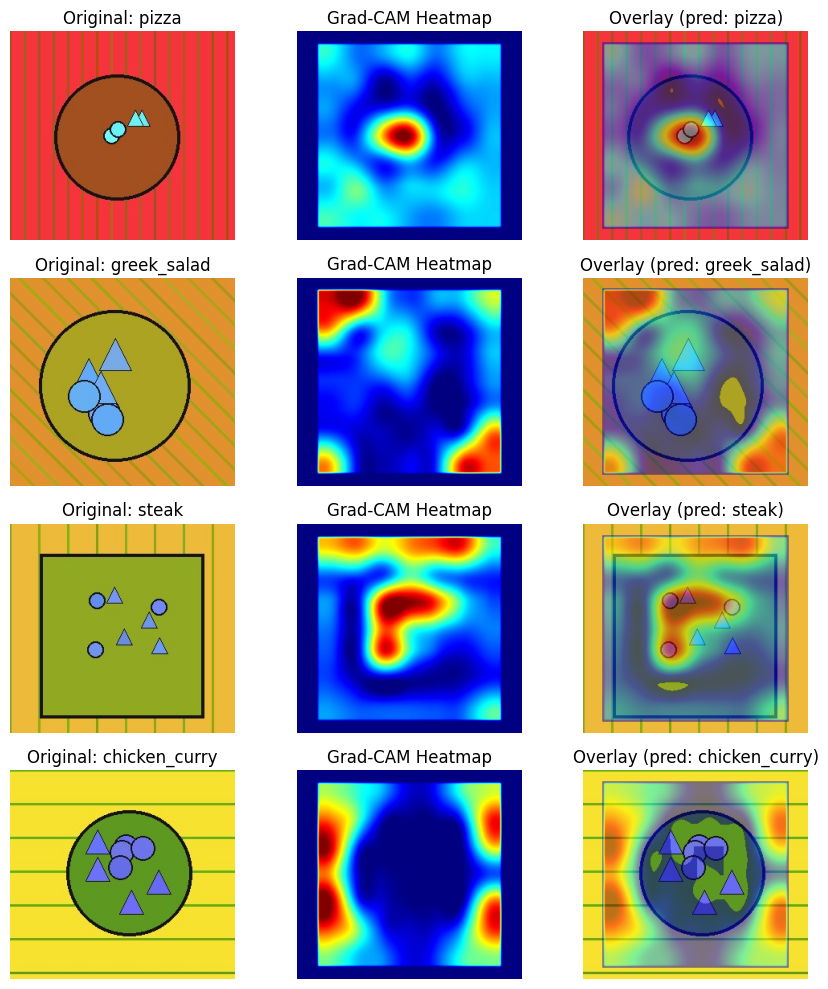

In [7]:
sample_classes = ["pizza", "greek_salad", "steak", "chicken_curry"]
fig, axes = plt.subplots(len(sample_classes), 3, figsize=(9, 10))

with GradCAM(model, target_layer) as gcam:
    for row, dish in enumerate(sample_classes):
        cls_idx = CLASSES.index(dish)
        img_path = next(p for p, l in test_samples if l == cls_idx)
        rgb = load_rgb(img_path)
        x = torch.from_numpy(eval_numpy(rgb)).unsqueeze(0)
        cam, pred_idx = gcam(x)
        heat_rgba, overlay = render_overlay(cam, rgb)
        axes[row, 0].imshow(rgb)
        axes[row, 0].set_title(f"Original: {dish}")
        axes[row, 1].imshow(heat_rgba[..., :3])
        axes[row, 1].set_title("Grad-CAM Heatmap")
        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title(f"Overlay (pred: {CLASSES[pred_idx]})")
        for col in range(3):
            axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [8]:
failures = []
with GradCAM(model, target_layer) as gcam:
    for path, true_lbl in test_samples:
        rgb = load_rgb(path)
        x = torch.from_numpy(eval_numpy(rgb)).unsqueeze(0)
        with torch.no_grad():
            probs = torch.softmax(model(x), dim=1)[0]
            pred_lbl = int(probs.argmax().item())
        if pred_lbl != true_lbl:
            cam, _ = gcam(x, target_index=pred_lbl)
            _, overlay = render_overlay(cam, rgb)
            failures.append((rgb, overlay, CLASSES[true_lbl], CLASSES[pred_lbl], float(probs[pred_lbl].item())))
        if len(failures) >= 6:
            break

if failures:
    fig, axes = plt.subplots(2, min(3, len(failures)), figsize=(11, 6))
    axes_flat = np.atleast_1d(axes).flat
    for ax, (_, ov, t_name, p_name, conf) in zip(axes_flat, failures):
        ax.imshow(ov)
        ax.set_title(f"True: {t_name}\nPred: {p_name} ({conf:.0%})", fontsize=9)
        ax.axis("off")
    plt.suptitle("Misclassified Examples (Grad-CAM on Predicted Class)", fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("No misclassifications found in scanned subset.")

No misclassifications found in scanned subset.


## 4. Production Reference Note

The `GradCAM`, `disable_inplace`, and `render_overlay` functions defined in Section 1 of this notebook are the exact reference implementation deployed in `backend/app/services/gradcam.py`.